In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent
sys.path.insert(0, str(PROJECT_ROOT))

from py_files import GallenModel_v1, Landslidev2_Old, metrics, train
import importlib
from typing import Optional
importlib.reload(GallenModel_v1)
importlib.reload(Landslidev2_Old)
importlib.reload(metrics)
importlib.reload(train)
from py_files.train import train_model_folds, train_model_folds_no_pga_dce, train_model_folds_no_pga
from sklearn.metrics import confusion_matrix
import tensorflow as tf
import numpy as np
from tensorflow.keras.models import load_model
from py_files.data import dataframe_to_dataset
from imblearn.over_sampling import SMOTE
from imblearn import pipeline, under_sampling
import keras_tuner as kt
import sklearn
from sklearn.model_selection import train_test_split
from matplotlib import pyplot as plt
import geopandas as gpd
import seaborn as sns
import pandas as pd
import contextily as cx
from py_files.data import NormalizationLayer
from py_files.metrics import plot_distribution, plot_susceptibility_map, plot_landslide_distribution
from py_files.GallenModel_v1 import  NewmarkActivation, DisplacementLayer, LandslideActivationLayer, CohesionLayer, InternalFrictionLayer
from py_files.Landslidev2_Old import DiceCrossEntropyLoss

In [2]:
df = gpd.read_file('~/Documents/ml-prep/ML-PREP-2025/learn/data/SU_15_Training1.gpkg')
df.drop(columns=['landslide_probability', 'landslide_preds', 'confusion', 'sus_pinn_landslide', 'sus_pinn_ground truth', 'ds', 'cohesion', 'internal_friction'], inplace=True)

In [3]:
df = df[df['Slope_mean'] >= 10]

In [4]:
columns = list(df.columns)
columns

['DN',
 'BD_mean',
 'Clay_mean',
 'Sand_mean',
 'Silt_mean',
 'NDVI_mean',
 'Est_mean',
 'Nrt_mean',
 'HorCurv_mean',
 'VertCurv_mean',
 'Slope_mean',
 'Elev_mean',
 'SoilThc_mean',
 'DistFlt_min',
 'LULC_majority',
 'TWI_mean',
 'PGA2_max',
 'PGA1_max',
 'Prc_mean',
 'Distrv_min',
 'distrd_min',
 'Soil Type',
 'BUK_mean',
 'landslide',
 'descriptio',
 'type',
 'geometry']

In [5]:
df.dropna(subset=list(columns), inplace=True) #cleans the dataframe by removing null rows for all columns

In [6]:
cols_remove = ['DN', 'BD_mean', 'geometry', 'PGA2_max', 'Soil Type', 'description', 'descriptio']
columns = [col for col in list(columns) if col not in cols_remove]
sampling_columns = [col for col in columns if col != 'landslide' and col != 'type']
columns

['Clay_mean',
 'Sand_mean',
 'Silt_mean',
 'NDVI_mean',
 'Est_mean',
 'Nrt_mean',
 'HorCurv_mean',
 'VertCurv_mean',
 'Slope_mean',
 'Elev_mean',
 'SoilThc_mean',
 'DistFlt_min',
 'LULC_majority',
 'TWI_mean',
 'PGA1_max',
 'Prc_mean',
 'Distrv_min',
 'distrd_min',
 'BUK_mean',
 'landslide',
 'type']

In [7]:
model = load_model("/Users/giogonzales/Documents/ml-prep/ML-PREP-2025/learn/trainedWeights/trainedCotabatoPhase7/historical/v4-1-1dce/fold-4-model-0.keras")

In [8]:
dataset = dataframe_to_dataset(df[columns], shuffle=False)
susceptibility_prediction = model.predict(dataset)

1778/1778 ━━━━━━━━━━━━━━━━━━━━ 1s 529us/step


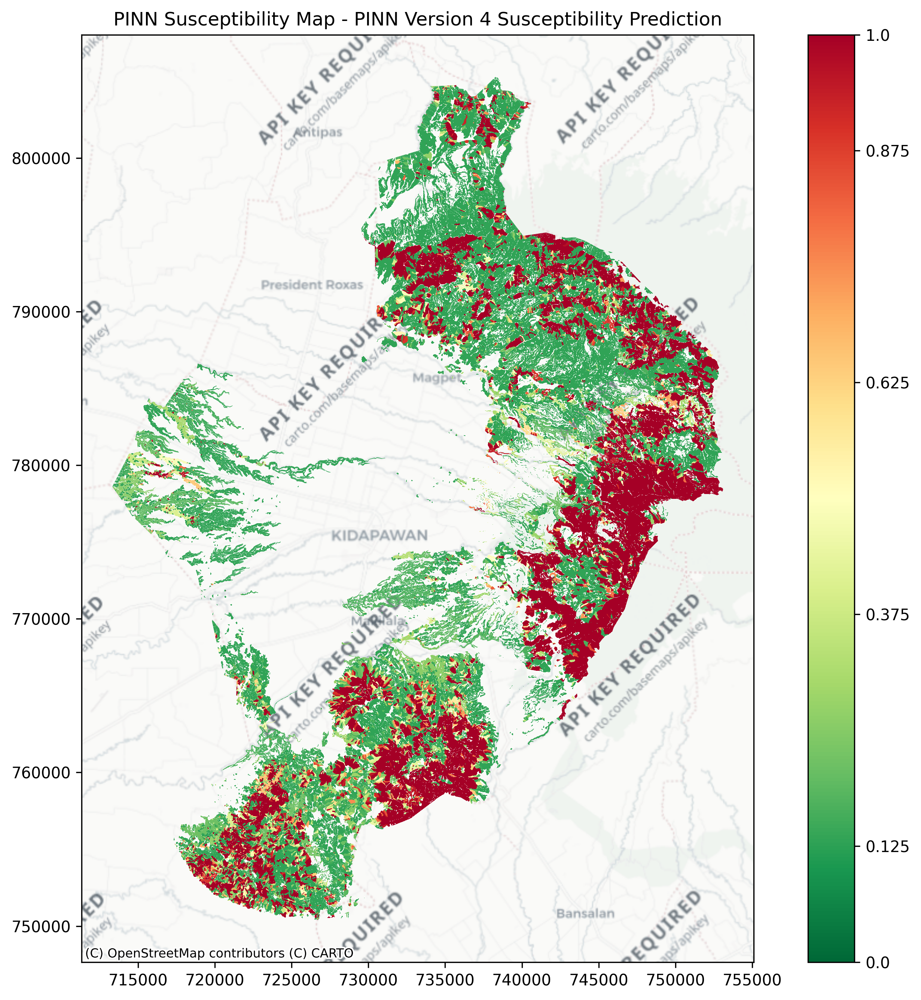

In [9]:
plot_susceptibility_map(df, susceptibility_prediction, "PINN Version 4 Susceptibility Prediction")

In [11]:
validation_df = gpd.read_file('~/Documents/ml-prep/ML-PREP-2025/learn/data/SU_15_Validation1.gpkg')
validation_df.drop(columns=['landslide_probability', 'landslide_preds', 'confusion', 'sus_pinn_landslide', 'sus_pinn_ground truth', 'ds', 'cohesion', 'internal_friction', 'descriptio'], inplace=True)
validation_df['type'].head()

0    Undifferentiated
1    Undifferentiated
2    Undifferentiated
3    Undifferentiated
4    Undifferentiated
Name: type, dtype: object

In [12]:
validation_df = validation_df[validation_df['Slope_mean'] >= 10]

In [13]:
validation_df_columns = list(validation_df.columns)
validation_df_columns

['DN',
 'BD_mean',
 'Clay_mean',
 'Sand_mean',
 'Silt_mean',
 'NDVI_mean',
 'Est_mean',
 'Nrt_mean',
 'HorCurv_mean',
 'VertCurv_mean',
 'Slope_mean',
 'Elev_mean',
 'SoilThc_mean',
 'DistFlt_min',
 'LULC_majority',
 'TWI_mean',
 'PGA2_max',
 'PGA1_max',
 'Prc_mean',
 'Distrv_min',
 'distrd_min',
 'Soil Type',
 'BUK_mean',
 'landslide',
 'type',
 'geometry']

In [14]:
validation_df.dropna(subset=list(validation_df_columns), inplace=True) #cleans the dataframe by removing null rows for all columns

In [15]:
columns = [col for col in columns if col not in ['descriptio', 'predicted_susceptibility', 'DN', 'geometry', 'Soil Type', 'PGA2_max']]
print(columns)
validation_ds = dataframe_to_dataset(validation_df[columns], shuffle=False)
susceptibility_prediction = model.predict(validation_ds)

['Clay_mean', 'Sand_mean', 'Silt_mean', 'NDVI_mean', 'Est_mean', 'Nrt_mean', 'HorCurv_mean', 'VertCurv_mean', 'Slope_mean', 'Elev_mean', 'SoilThc_mean', 'DistFlt_min', 'LULC_majority', 'TWI_mean', 'PGA1_max', 'Prc_mean', 'Distrv_min', 'distrd_min', 'BUK_mean', 'landslide', 'type']
7534/7534 ━━━━━━━━━━━━━━━━━━━━ 4s 487us/step


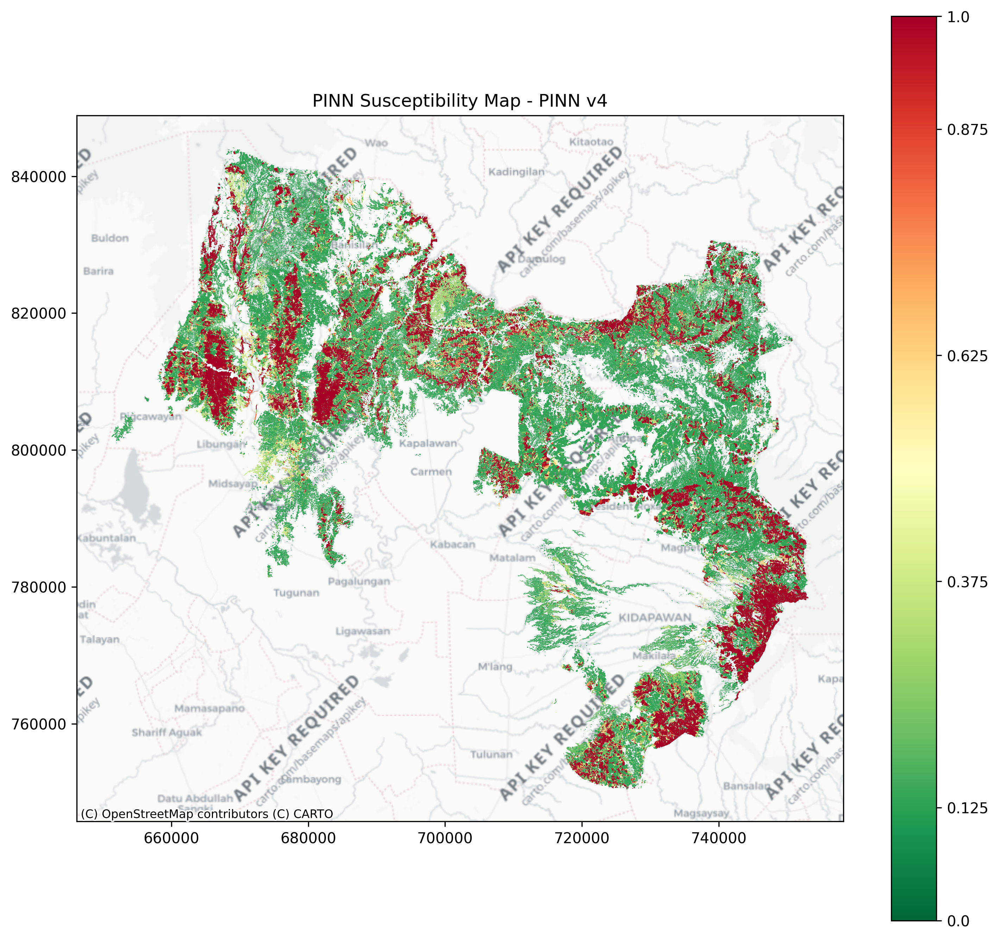

In [16]:
plot_susceptibility_map(validation_df, susceptibility_prediction, "PINN v4")

In [21]:
validation_df["predicted_susceptibility"] = susceptibility_prediction
validation_df.columns
validation_df.to_file("../pinn-dce.gpkg", driver="GPKG")

7534/7534 ━━━━━━━━━━━━━━━━━━━━ 4s 497us/step


KeyboardInterrupt: 

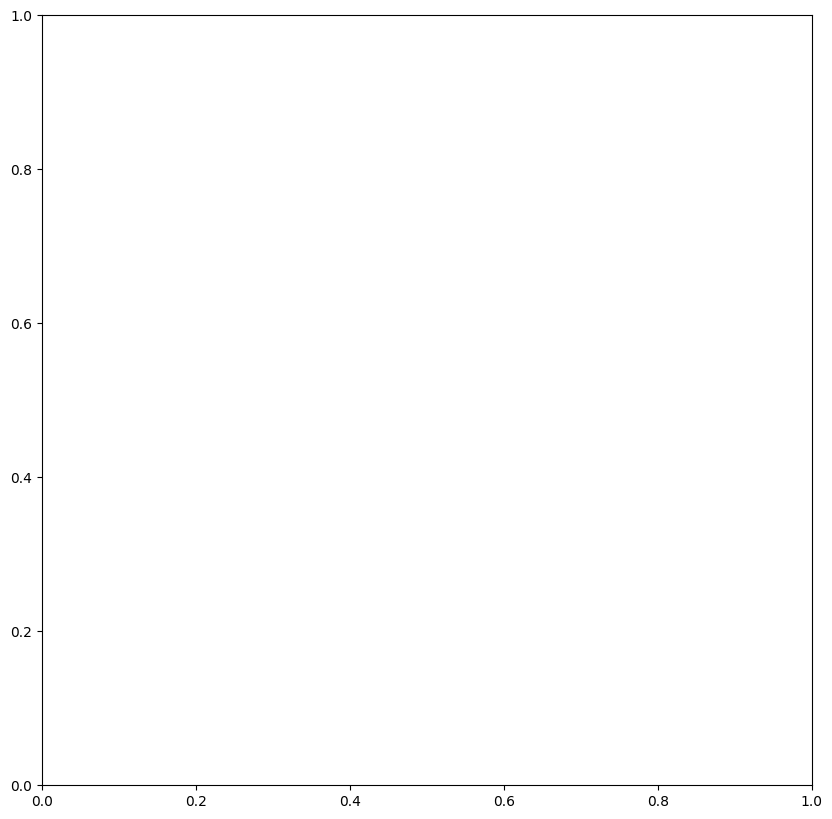

In [18]:
#Extract Geotechnical estimation of the model
df_wm = validation_df.to_crs(epsg=3857)
cohesion_model = tf.keras.Model(inputs=model.inputs, outputs=model.get_layer("cohesion_layer").output)
predicted_cohesion = cohesion_model.predict(validation_ds)
df_wm['estimated_cohesion'] = predicted_cohesion

ax = df_wm.plot(column="estimated_cohesion", legend=True, figsize=(10, 10), alpha=0.7)
cx.add_basemap(ax,source='NASAGIBS.ASTER_GDEM_Greyscale_Shaded_Relief')
print(f"Predicted cohesion length: {len(predicted_cohesion)}")
df_wm['estimated_cohesion'].min(), df_wm['estimated_cohesion'].max()


7534/7534 ━━━━━━━━━━━━━━━━━━━━ 4s 510us/step


(np.float32(0.021542322), np.float32(0.9980173))

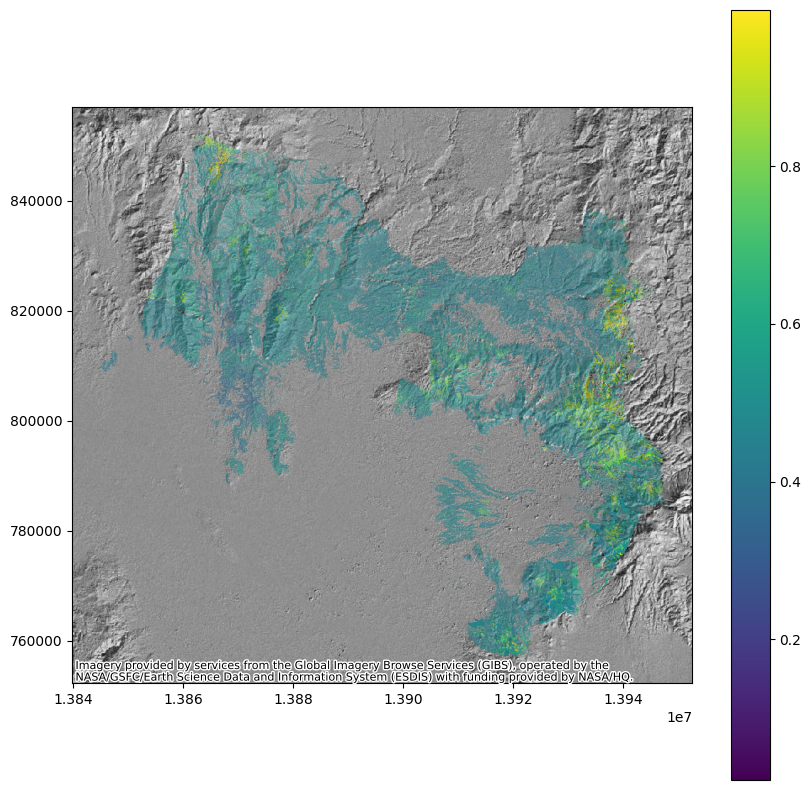

In [ ]:
df_wm = validation_df.to_crs(epsg=3857)
friction_model = tf.keras.Model(inputs=model.input, outputs=model.get_layer("internal_friction").output)
geotech_preds = friction_model.predict(validation_ds)
df_wm["ifi"] = geotech_preds
ax = df_wm.plot(column="ifi", legend=True, figsize=(10, 10), alpha=0.7)
cx.add_basemap(ax,source='NASAGIBS.ASTER_GDEM_Greyscale_Shaded_Relief')

df_wm['ifi'].min(), df_wm['ifi'].max()

In [ ]:
model.summary()

Model: "functional_14"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ type (InputLayer)   │ (None, 1)         │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Clay_mean           │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Sand_mean           │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Silt_mean           │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ NDVI_mean           │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Est_mean            │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Nrt_mean            │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ HorCurv_mean        │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ VertCurv_mean       │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Slope_mean          │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Elev_mean           │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ SoilThc_mean        │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ DistFlt_min         │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ LULC_majority       │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ TWI_mean            │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Prc_mean            │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Distrv_min          │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                 

 Total params: 31,062 (121.41 KB)

 Trainable params: 10,170 (39.73 KB)

 Non-trainable params: 550 (2.22 KB)

 Optimizer params: 20,342 (79.46 KB)

In [ ]:
landslide_df = validation_df[validation_df['landslide'] == 1]
landslide_data_len = landslide_df.shape[0]

landslide_df = landslide_df.sample(landslide_data_len // 2, random_state=42)

print(f"Landslide DF shape: {landslide_df.shape}")

non_landslide_df = validation_df[validation_df['landslide'] == 0]
non_landslide_df = non_landslide_df.sample(landslide_df.shape[0], random_state=42)

for_feature = pd.concat([landslide_df, non_landslide_df], ignore_index=True)


Landslide DF shape: (2880, 27)


In [ ]:
columns = [col for col in columns if col != 'PGA1_max']
import shap

def df_to_input_dict(df):
    inputs = {}
    
    for inp in model.input:
        name = inp.name.split(":")[0]
        
        col = df[name].values.reshape(-1, 1)
        
        if inp.dtype == tf.string:
            col = col.astype(str)
            col = tf.convert_to_tensor(col, dtype=tf.string)
        else:
            col = tf.convert_to_tensor(col, dtype=tf.float32)

        inputs[name] = col
    return inputs


def df_to_input_list_multi(df):
    inputs = []
    for inp in model.input:
        name = inp.name.split(":")[0]

        col = df[name].values.reshape(-1, 1)

        if inp.dtype == tf.string:
            # categorical input: convert to string
            col = col.astype(str)
        else:
            # numeric input: convert to float32
            col = col.astype(np.float32)

        inputs.append(col)

    return inputs

feature_names = [col for col in columns if col != 'landslide']
feature_names.append("PGA1_max")
print(f"Feature names: {feature_names}")
def model_predict(df_dict):
    inputs = {}

    np_arr = np.array(df_dict)
    np_arr = np.stack(np_arr, axis=1)

    for inp, arr in zip(model.input, np_arr):
    
        name = inp.name.split(":")[0]
        if name == 'type':
            inputs[name] = arr
            continue

        inputs[name] = arr.astype(np.float32)

    print(inputs)
    print(np_arr.shape)

    return model.predict(inputs)

background_inputs = df_to_input_list_multi(validation_df.sample(100, random_state=42))
background_ds = dataframe_to_dataset(validation_df.sample(100, random_state=42)[columns])

test_inputs = df_to_input_list_multi(validation_df)
test_inputs_ds = dataframe_to_dataset(validation_df[columns])


print(f"Model inputs len:{len(model.input)}")
print(f"Background inputs len:{len(background_inputs)}")

explainer = shap.KernelExplainer(model=model_predict, data=for_feature.sample(100, random_state=42)[feature_names].values, feature_names=feature_names)

# Compute SHAP values for test data
shap_values = explainer.shap_values(for_feature[feature_names])
X_test = validation_df[feature_names].to_numpy()


/Users/giogonzales/Documents/ml-prep/mlprep/venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Feature names: ['Clay_mean', 'Sand_mean', 'Silt_mean', 'NDVI_mean', 'Est_mean', 'Nrt_mean', 'HorCurv_mean', 'VertCurv_mean', 'Slope_mean', 'Elev_mean', 'SoilThc_mean', 'DistFlt_min', 'LULC_majority', 'TWI_mean', 'Prc_mean', 'Distrv_min', 'distrd_min', 'BUK_mean', 'type', 'PGA1_max']
Model inputs len:20
Background inputs len:20
{'Clay_mean': array([360.22852, 393.     , 375.48074, 417.09763, 402.3954 , 382.75394,
       338.48694, 369.61115, 407.     , 362.53067, 346.02438, 355.     ,
       382.2668 , 372.9125 , 363.     , 357.61798, 356.61557, 347.02158,
       348.0895 , 385.1068 , 352.5397 , 361.     , 378.03705, 429.61368,
       412.97415, 342.5    , 373.05804, 361.16394, 391.     , 364.75876,
       369.86038, 361.1235 , 357.93152, 345.6808 , 378.67648, 416.00427,
       352.     , 395.08533, 338.47375, 365.26376, 361.     , 340.     ,
       341.477  , 361.18802, 317.     , 359.     , 339.98224, 365.10693,
       370.4825 , 342.     , 389.26505, 379.4344 , 372.     , 369.20734,


  0%|          | 0/5760 [00:00<?, ?it/s]

{'Clay_mean': array([364.34012], dtype=float32), 'Sand_mean': array([335.31976], dtype=float32), 'Silt_mean': array([301.], dtype=float32), 'NDVI_mean': array([0.83488363], dtype=float32), 'Est_mean': array([0.9805108], dtype=float32), 'Nrt_mean': array([0.001077], dtype=float32), 'HorCurv_mean': array([0.0043578], dtype=float32), 'VertCurv_mean': array([-0.00043915], dtype=float32), 'Slope_mean': array([38.513718], dtype=float32), 'Elev_mean': array([647.7407], dtype=float32), 'SoilThc_mean': array([18.853655], dtype=float32), 'DistFlt_min': array([5086.5806], dtype=float32), 'LULC_majority': array([10.], dtype=float32), 'TWI_mean': array([2.7098277], dtype=float32), 'Prc_mean': array([176.60065], dtype=float32), 'Distrv_min': array([241.86774], dtype=float32), 'distrd_min': array([241.86774], dtype=float32), 'BUK_mean': array([11.618873], dtype=float32), 'type': array(['Sandy Clay Loam'], dtype=object), 'PGA1_max': array([0.27013817], dtype=float32)}
(20, 1)
1/1 ━━━━━━━━━━━━━━━━━━━━ 

/Users/giogonzales/Documents/ml-prep/mlprep/venv/lib/python3.12/site-packages/shap/explainers/_kernel.py:706: RuntimeWarning: divide by zero encountered in matmul
  w = np.linalg.solve(X.T @ WX, WX.T @ y)
/Users/giogonzales/Documents/ml-prep/mlprep/venv/lib/python3.12/site-packages/shap/explainers/_kernel.py:706: RuntimeWarning: overflow encountered in matmul
  w = np.linalg.solve(X.T @ WX, WX.T @ y)
/Users/giogonzales/Documents/ml-prep/mlprep/venv/lib/python3.12/site-packages/shap/explainers/_kernel.py:706: RuntimeWarning: invalid value encountered in matmul
  w = np.linalg.solve(X.T @ WX, WX.T @ y)
  0%|          | 1/5760 [00:04<7:54:16,  4.94s/it]

{'Clay_mean': array([379.5894], dtype=float32), 'Sand_mean': array([333.54343], dtype=float32), 'Silt_mean': array([287.20218], dtype=float32), 'NDVI_mean': array([0.71146536], dtype=float32), 'Est_mean': array([-0.96563625], dtype=float32), 'Nrt_mean': array([0.01181665], dtype=float32), 'HorCurv_mean': array([0.00017291], dtype=float32), 'VertCurv_mean': array([0.00015602], dtype=float32), 'Slope_mean': array([25.465841], dtype=float32), 'Elev_mean': array([482.57803], dtype=float32), 'SoilThc_mean': array([20.761383], dtype=float32), 'DistFlt_min': array([1760.0568], dtype=float32), 'LULC_majority': array([17.], dtype=float32), 'TWI_mean': array([3.0373857], dtype=float32), 'Prc_mean': array([176.60065], dtype=float32), 'Distrv_min': array([335.4102], dtype=float32), 'distrd_min': array([322.4903], dtype=float32), 'BUK_mean': array([11.2735615], dtype=float32), 'type': array(['Sandy Clay Loam'], dtype=object), 'PGA1_max': array([0.32319936], dtype=float32)}
(20, 1)
1/1 ━━━━━━━━━━━━━

... (4,504 outputs left out)

 39%|███▉      | 2254/5760 [2:25:12<3:58:08,  4.08s/it]

{'Clay_mean': array([368.02148], dtype=float32), 'Sand_mean': array([308.50385], dtype=float32), 'Silt_mean': array([323.47467], dtype=float32), 'NDVI_mean': array([0.78898257], dtype=float32), 'Est_mean': array([-0.15219307], dtype=float32), 'Nrt_mean': array([-0.11142351], dtype=float32), 'HorCurv_mean': array([0.00471013], dtype=float32), 'VertCurv_mean': array([-0.00073003], dtype=float32), 'Slope_mean': array([26.428627], dtype=float32), 'Elev_mean': array([280.09372], dtype=float32), 'SoilThc_mean': array([14.06], dtype=float32), 'DistFlt_min': array([0.], dtype=float32), 'LULC_majority': array([10.], dtype=float32), 'TWI_mean': array([2.5392544], dtype=float32), 'Prc_mean': array([176.60065], dtype=float32), 'Distrv_min': array([375.89893], dtype=float32), 'distrd_min': array([384.70767], dtype=float32), 'BUK_mean': array([11.023681], dtype=float32), 'type': array(['Sandy Clay Loam'], dtype=object), 'PGA1_max': array([0.27177128], dtype=float32)}
(20, 1)
1/1 ━━━━━━━━━━━━━━━━━━━━

 39%|███▉      | 2254/5760 [2:25:12<3:45:52,  3.87s/it]


KeyboardInterrupt: 

Shap values: (5760, 20)
length of features: 20
length of For feature: (5760, 20)
2 (5760, 20)
Feature names shape: 20


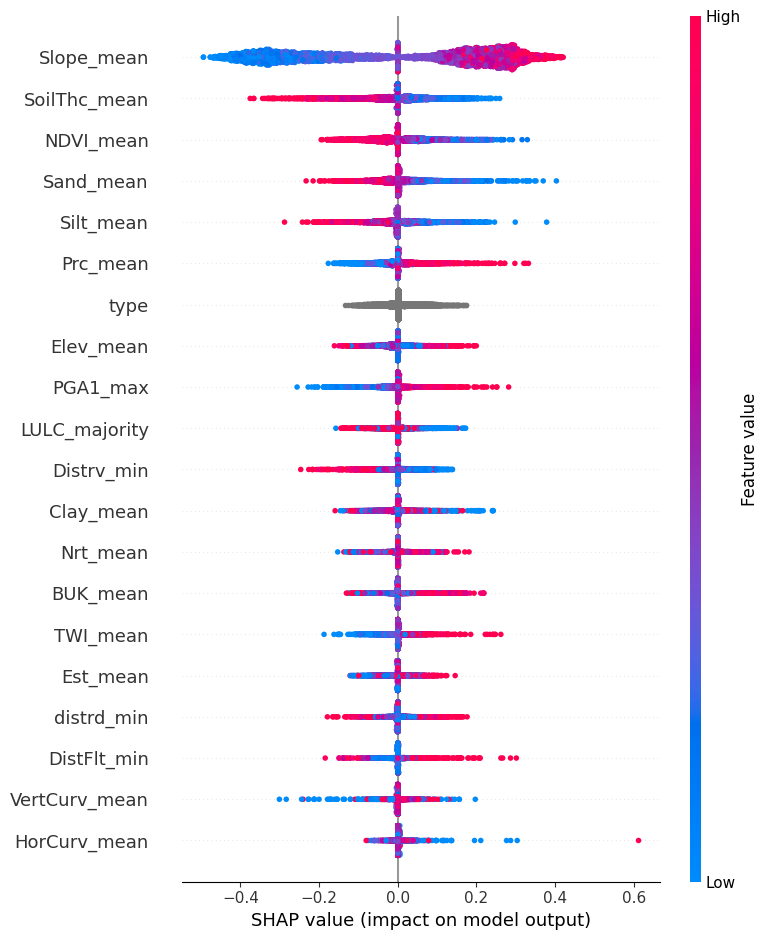

<Figure size 640x480 with 0 Axes>

In [ ]:
# Plot summary plot
X_test = for_feature[feature_names].to_numpy()
shap_values = np.array(shap_values)
shap_values = np.squeeze(shap_values)   # removes extra (1,1) dims
shap_values = shap_values.T
print(f"Shap values: {shap_values.shape}")
print(f"length of features: {len(feature_names)}")
print(f"length of For feature: {for_feature[feature_names].shape}")
print(shap_values.ndim, shap_values.shape)
# feature_names = [feature for feature in feature_names if feature != 'PGA1_max']
print(f"Feature names shape: {len(feature_names)}")
shap.summary_plot(shap_values, X_test, feature_names=feature_names)
plt.tight_layout()
plt.savefig(f'/Users/giogonzales/Documents/ml-prep/ML-PREP-2025/learn/figures/v2/historical/pinn-phase7-feature-importance.png', format="png")
